<a href="https://colab.research.google.com/github/oxjun/Klasifikasi_Beras_MobileNetV3/blob/main/Klasifikasi_Beras_MobileNetV3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')

dataset_dir = '/content/drive/MyDrive/Beras'
if os.path.exists(dataset_dir):
    print("Folder 'Beras' ditemukan:", os.listdir(dataset_dir))

Mounted at /content/drive
Folder 'Beras' ditemukan: ['Ipsala', 'Jasmine', 'Basmati', 'Arborio', 'Karacadag']


In [2]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir, validation_split=0.2, subset="training", seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir, validation_split=0.2, subset="validation", seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)

val_batches = tf.data.experimental.cardinality(val_test_ds)
val_ds = val_test_ds.take(val_batches // 2)
test_ds = val_test_ds.skip(val_batches // 2)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 10000 files belonging to 5 classes.
Using 8000 files for training.
Found 10000 files belonging to 5 classes.
Using 2000 files for validation.


In [3]:
from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
])

base_model = tf.keras.applications.MobileNetV3Large(
    input_shape=(224, 224, 3), include_top=False, weights='imagenet', include_preprocessing=True
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    "best_mobilenetv3_beras.keras",
    save_best_only=True,
    monitor="val_accuracy",
    mode="max"
)

EPOCHS = 100
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint_cb]
)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1042s 505ms/step - accuracy: 0.8547 - loss: 0.4392 - val_accuracy: 0.9637 - val_loss: 0.1502
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - accuracy: 0.9690 - loss: 0.1191 - val_accuracy: 0.9819 - val_loss: 0.0850
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.9825 - loss: 0.0794 - val_accuracy: 0.9909 - val_loss: 0.0497
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 52ms/step - accuracy: 0.9816 - loss: 0.0692 - val_accuracy: 0.9909 - val_loss: 0.0427
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.9849 - loss: 0.0586 - val_accuracy: 0.9909 - val_loss: 0.0419
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 14s 57ms/step - accuracy: 0.9869 - loss: 0.0493 - val_accuracy: 0.9940 - val_loss: 0.0329
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - accuracy: 0.9872 - loss: 0.0469 - val_accuracy: 0.9929 - val_loss: 0.0343
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.9865 - loss

HASIL EVALUASI AKHIR MODEL MOBILENETV3 (100 EPOCH)
Precision Score : 0.9912 (99.12%)
Recall Score    : 0.9911 (99.11%)
F1 Score        : 0.9911 (99.11%)

Classification Report Detail per Kelas:
              precision    recall  f1-score   support

     Arborio     0.9789    0.9947    0.9867       187
     Basmati     0.9841    1.0000    0.9920       186
      Ipsala     0.9955    1.0000    0.9978       223
     Jasmine     1.0000    0.9739    0.9868       230
   Karacadag     0.9945    0.9890    0.9917       182

    accuracy                         0.9911      1008
   macro avg     0.9906    0.9915    0.9910      1008
weighted avg     0.9912    0.9911    0.9911      1008



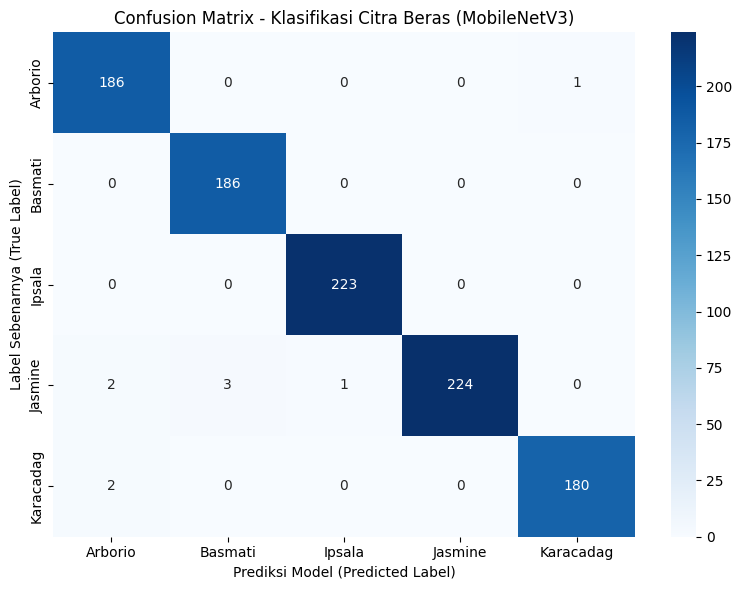

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score

# 1. Memuat kembali model terbaik yang sudah disimpan otomatis oleh checkpoint
best_model = tf.keras.models.load_model("best_mobilenetv3_beras.keras")

y_true = []
y_pred = []

# Mengambil prediksi dari test_ds (data testing yang belum pernah dilihat model)
for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 2. Menghitung Metrik Utama (Weighted)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("=" * 50)
print("HASIL EVALUASI AKHIR MODEL MOBILENETV3 (100 EPOCH)")
print("=" * 50)
print(f"Precision Score : {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall Score    : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score        : {f1:.4f} ({f1*100:.2f}%)")
print("=" * 50)

# 3. Laporan Detail per Kelas
print("\nClassification Report Detail per Kelas:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# 4. Membuat Gambar Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Klasifikasi Citra Beras (MobileNetV3)')
plt.xlabel('Prediksi Model (Predicted Label)')
plt.ylabel('Label Sebenarnya (True Label)')
plt.tight_layout()
plt.savefig('confusion_matrix_mobilenetv3.png', dpi=300)
plt.show()

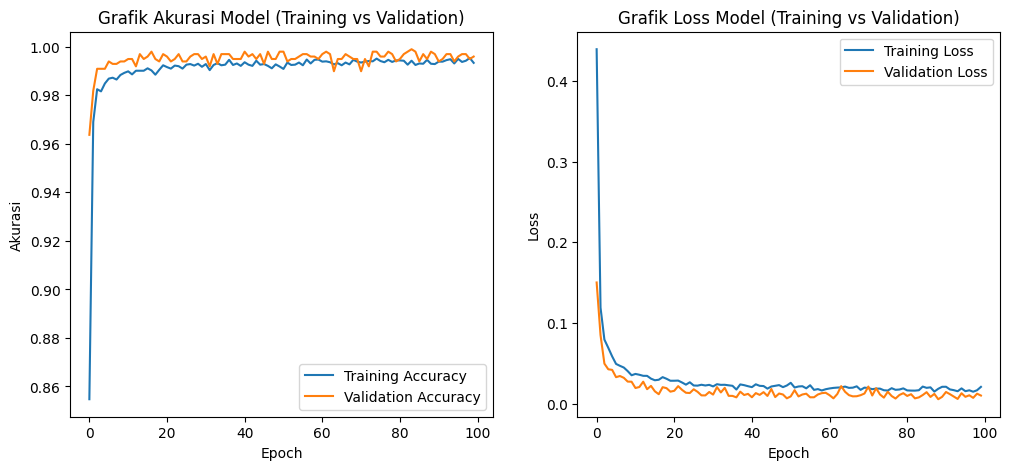

In [6]:
import matplotlib.pyplot as plt

# Mengambil riwayat akurasi dan loss dari variabel history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Grafik 1: Akurasi (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Model (Training vs Validation)')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')

# Grafik 2: Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Grafik Loss Model (Training vs Validation)')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()